In [ ]:
R.version.string

[1] "R version 4.2.2 Patched (2022-11-10 r83330)"

In [ ]:
print(installed.packages())

              Package         LibPath                         Version   
IRdisplay     "IRdisplay"     "/usr/local/lib/R/site-library" "1.1"     
IRkernel      "IRkernel"      "/usr/local/lib/R/site-library" "1.3.1"   
pbdZMQ        "pbdZMQ"        "/usr/local/lib/R/site-library" "0.3-8"   
repr          "repr"          "/usr/local/lib/R/site-library" "1.1.4"   
askpass       "askpass"       "/usr/lib/R/site-library"       "1.1"     
assertthat    "assertthat"    "/usr/lib/R/site-library"       "0.2.1"   
backports     "backports"     "/usr/lib/R/site-library"       "1.4.1"   
base64enc     "base64enc"     "/usr/lib/R/site-library"       "0.1-3"   
bit           "bit"           "/usr/lib/R/site-library"       "4.0.4"   
bit64         "bit64"         "/usr/lib/R/site-library"       "4.0.5"   
blob          "blob"          "/usr/lib/R/site-library"       "1.2.3"   
brew          "brew"          "/usr/lib/R/site-library"       "1.0-8"   
brio          "brio"          "/usr/lib/R/site-libr

In [ ]:
install.packages("tidyverse")
install.packages("tidyquant")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘future.apply’, ‘numDeriv’, ‘progressr’, ‘SQUAREM’, ‘lava’, ‘prodlim’, ‘globals’, ‘later’, ‘listenv’, ‘parallelly’, ‘clock’, ‘gower’, ‘hardhat’, ‘ipred’, ‘furrr’, ‘htmlwidgets’, ‘crosstalk’, ‘promises’, ‘Rcpp’, ‘warp’, ‘BH’, ‘fracdiff’, ‘lmtest’, ‘tseries’, ‘urca’, ‘RcppArmadillo’, ‘RcppRoll’, ‘future’, ‘quadprog’, ‘zoo’, ‘recipes’, ‘rsample’, ‘plotly’, ‘padr’, ‘slider’, ‘anytime’, ‘forecast’, ‘tsfeatures’, ‘PerformanceAnalytics’, ‘quantmod’, ‘lazyeval’, ‘Quandl’, ‘riingo’, ‘alphavantager’, ‘timetk’, ‘timeDate’, ‘TTR’, ‘xts’


Warning message in install.packages("tidyquant"):
“installation of package ‘clock’ had non-zero exit status”
Warning message in install.packages("tidyquant"):
“installation of package ‘recipes’ had non-zero exit status”
Warning message in install.packages("tidyquant")

In [ ]:
library(tidyverse)
library(tidyquant)

Loading required package: lubridate


Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


Loading required package: PerformanceAnalytics

Loading required package: xts

Loading required package: zoo


Attaching package: ‘zoo’


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric



Attaching package: ‘xts’


The following objects are masked from ‘package:dplyr’:

    first, last



Attaching package: ‘PerformanceAnalytics’


The following object is masked from ‘package:graphics’:

    legend


Loading required package: quantmod

Loading required package: TTR

Registered S3 method overwritten by 'quantmod':
  method            from
  as.zoo.data.frame zoo 



In [ ]:
aapl <- tq_get('AAPL',
               from = "2017-01-01",
               to = "2022-11-13",
               get = "stock.prices")

In [ ]:
head(aapl)

symbol,date,open,high,low,close,volume,adjusted
<chr>,<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AAPL,2017-01-03,28.9500,29.0825,28.6900,29.0375,115127600,27.17475
AAPL,2017-01-04,28.9625,29.1275,28.9375,29.0050,84472400,27.14434
AAPL,2017-01-05,28.9800,29.2150,28.9525,29.1525,88774400,27.28238
AAPL,2017-01-06,29.1950,29.5400,29.1175,29.4775,127007600,27.58653
AAPL,2017-01-09,29.4875,29.8575,29.4850,29.7475,134247600,27.83921
AAPL,2017-01-10,29.6925,29.8450,29.5750,29.7775,97848400,27.86728


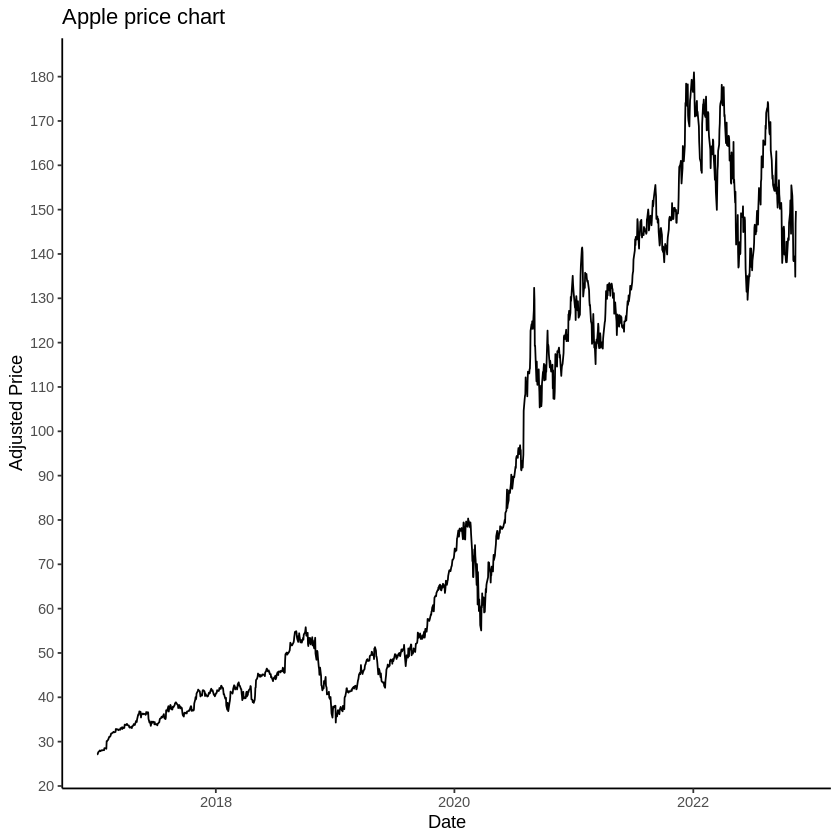

In [ ]:
aapl %>%
  ggplot(aes(x = date, y = adjusted)) +
  geom_line() +
  theme_classic() +
  labs(x = 'Date',
       y = "Adjusted Price",
       title = "Apple price chart") +
  scale_y_continuous(breaks = seq(0,300,10))

In [ ]:
tickers = c("AAPL", "NFLX", "AMZN", "MSFT", "TWTR")

prices <- tq_get(tickers,
                 from = "2017-01-01",
                 to = "2022-11-13",
                 get = "stock.prices")

Warning message:
“Removed 10 row(s) containing missing values (geom_path).”


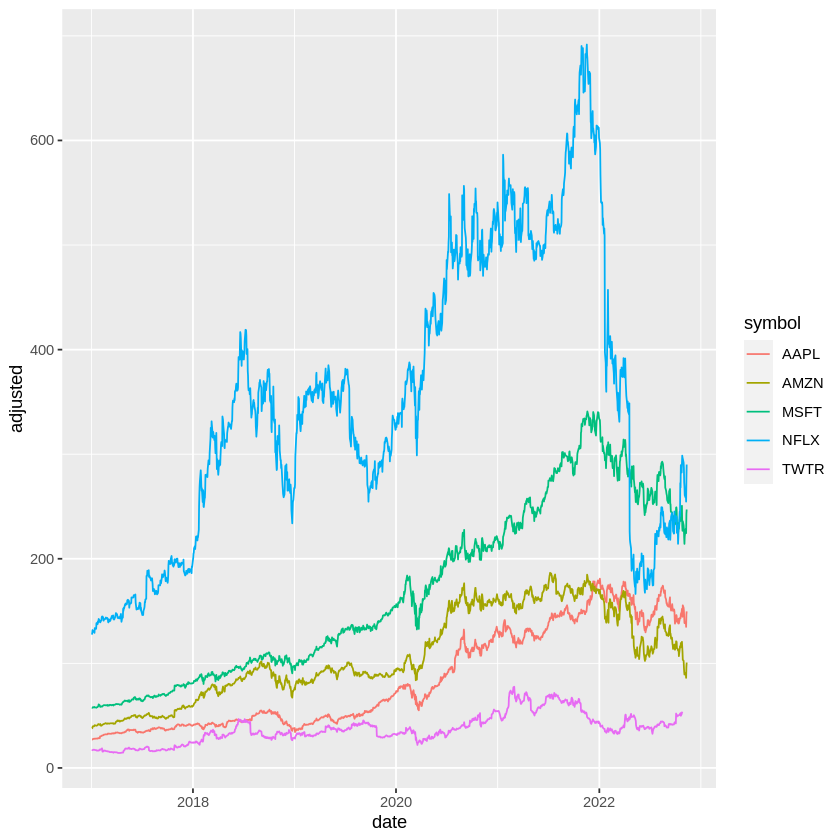

In [ ]:
prices %>%
  ggplot(aes(x = date, y = adjusted, color = symbol)) +
  geom_line()

Warning message:
“Removed 10 row(s) containing missing values (geom_path).”


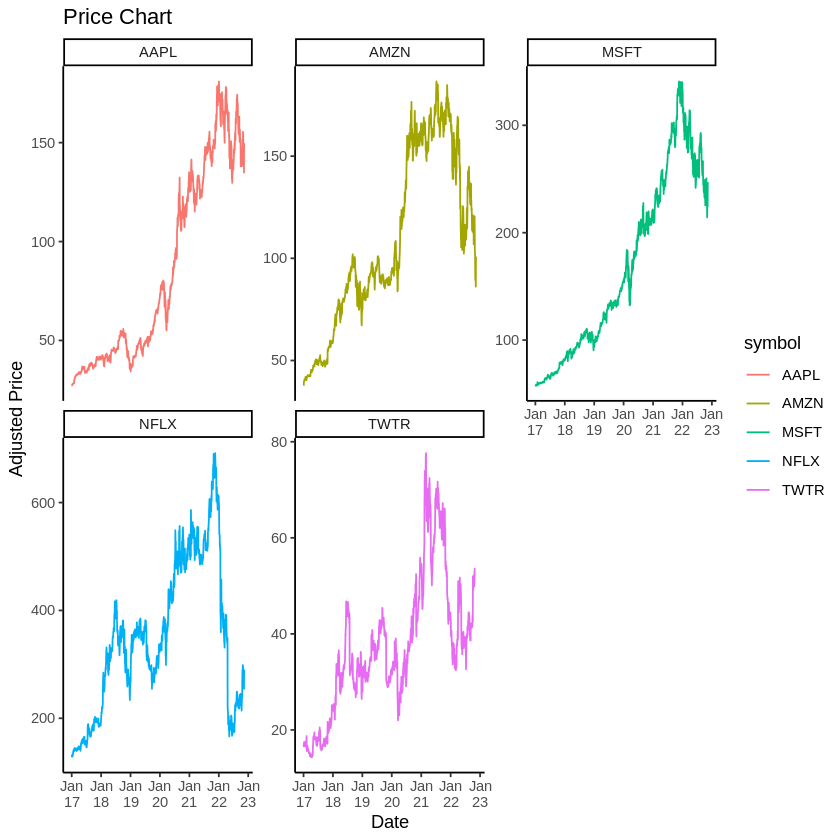

In [ ]:
prices %>%
  ggplot(aes(x = date, y = adjusted, color = symbol)) +
  geom_line() +
  facet_wrap(~symbol,scales = 'free_y') +
  theme_classic() +
  labs(x = 'Date',
       y = "Adjusted Price",
       title = "Price Chart") +
  scale_x_date(date_breaks = "year",
               date_labels = "%b\n%y")